In [1]:
# First compile with make and then create the wrapper as: 
# f2py -c global.f90 dist.f90 radsyn.f90 main.f90 -m jet
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt
import jet

In [2]:
# Read the data
eV = 1.6e-12
fname = 'data.dats'
data = np.loadtxt(fname, usecols=(0,1,2))
E_data = data[:,0] * eV
S_data = data[:,1]
errS_data = data[:,2]

In [3]:
# Define the function to fit
def model_sed(E, B):
    """Synchrotron model for energy vector E and magnetic field B"""
    fit_values = jet.sed_model(B, E) # The routine returns m_data_max values, as defined in global.f90
    return( fit_values[:len(E)])     # The only useful values are the first ones up to the number of points in E

In [4]:
# Define the seed values for fitting
seed = np.array([1.0]) # B...

# Fit the model to the data
popt, pcov = curve_fit(model_sed, xdata=E_data, ydata=S_data, p0=seed, sigma=errS_data, absolute_sigma=True)
#print(pcov)

perr = np.sqrt(np.diag(pcov))
#print(perr)

for i in range(len(perr)):
    print(str(popt[i])+' +- '+str(perr[i]))

0.010043103864217393 +- 0.0007065853656380843


In [5]:
# prepare confidence level curves
nstd = 3.0 # to draw 1-sigma intervals
popt_up = popt + nstd * perr
popt_dw = popt - nstd * perr

# Define the range in which the function (and the confidence interval) will be calculated in the plot
E_fit = np.geomspace(5.0e-8*eV, 2.0e4*eV, 20) # E_min, E_max, number of points
fit = model_sed(E_fit, *popt)
fit_up = model_sed(E_fit, *popt_up)
fit_dw = model_sed(E_fit, *popt_dw)
#fit, E_fit, S_data, E_data

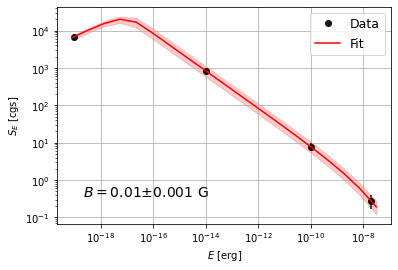

In [6]:
# Plot the data and the fit with a 1-sigma confidence interval 
fig, ax = plt.subplots(1)
plt.rcParams.update({'font.size': 14,
    "font.serif": ["Palatino"]})
plt.grid()
plt.gca().set_xlabel(r'$E$ [erg]')
plt.gca().set_ylabel(r'$S_E$ [cgs]')

# Plot the data set with its errorbars
plt.errorbar(E_data, S_data, yerr=errS_data, hold=True, ecolor='k', alpha=0.9, fmt='none')
plt.plot(E_data, S_data, 'ko', alpha=0.9, label = 'Data')

# Plot the fit and the 1-sigma confidence interval 
plt.plot(E_fit, fit, 'r-', label='Fit')
ax.fill_between(E_fit, fit_up, fit_dw, alpha=.2, label='', color='r')

plt.title('')
#plt.xlim(3, 500)
#plt.ylim(10, 500)

plt.legend(loc='best')
ax.legend(prop={"size":12.5}) 
ax.loglog() 

ax.annotate(r'$B =$' + str(round(abs(popt[0]),3)) + '$\pm$' + str(round(perr[0],3)) + ' G',
            xy=(0.02, 0.02), xycoords='axes fraction',
            xytext=(20, 20), textcoords='offset pixels',
            horizontalalignment='left',
            verticalalignment='bottom')

plt.show()

In [7]:
fig.savefig('fit.pdf', bbox_inches='tight')